# SciEntsBank: Exploratory Data Analysis

**Question:** How do class balance, question composition, answer length, and lexical relationships vary in the training data?

This notebook presents 14 measured descriptive views. It contains no AI model training or performance claims. Read the audit notebook first. All graphs use the official training data; official test records are not used for exploratory model selection.

In [1]:
from pathlib import Path
import subprocess
import sys

# Works from this checkout, a local Jupyter session, or a fresh Colab session.
roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in roots if (p / "data/raw/scientsbank_core.zip").exists()), None)
if ROOT is None:
    checkout = Path("/content/scientsbank_portfolio")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/Junghwan0516/early-learning-support.git",
                        str(checkout)], check=True)
    ROOT = checkout / "projects/science-answer-benchmark"
sys.path.insert(0, str(ROOT / "scripts"))
import json
import pandas as pd
from IPython.display import display, Image
from build_analysis import build
print(f"Project: {ROOT.name}")

Project: science-answer-benchmark


In [2]:
if not (ROOT / "reports/tables/audit_summary.json").exists():
    build()
train = pd.read_csv(ROOT / "data/processed/train.csv")
print(f"Training answer records: {len(train):,}")

Training answer records: 4,969


## 1. Class imbalance

Correct answers account for 40.41% of training records. A majority-class rule would achieve this training accuracy while missing every other class. The majority/minority count ratio is about 87.3; it is not a model result.

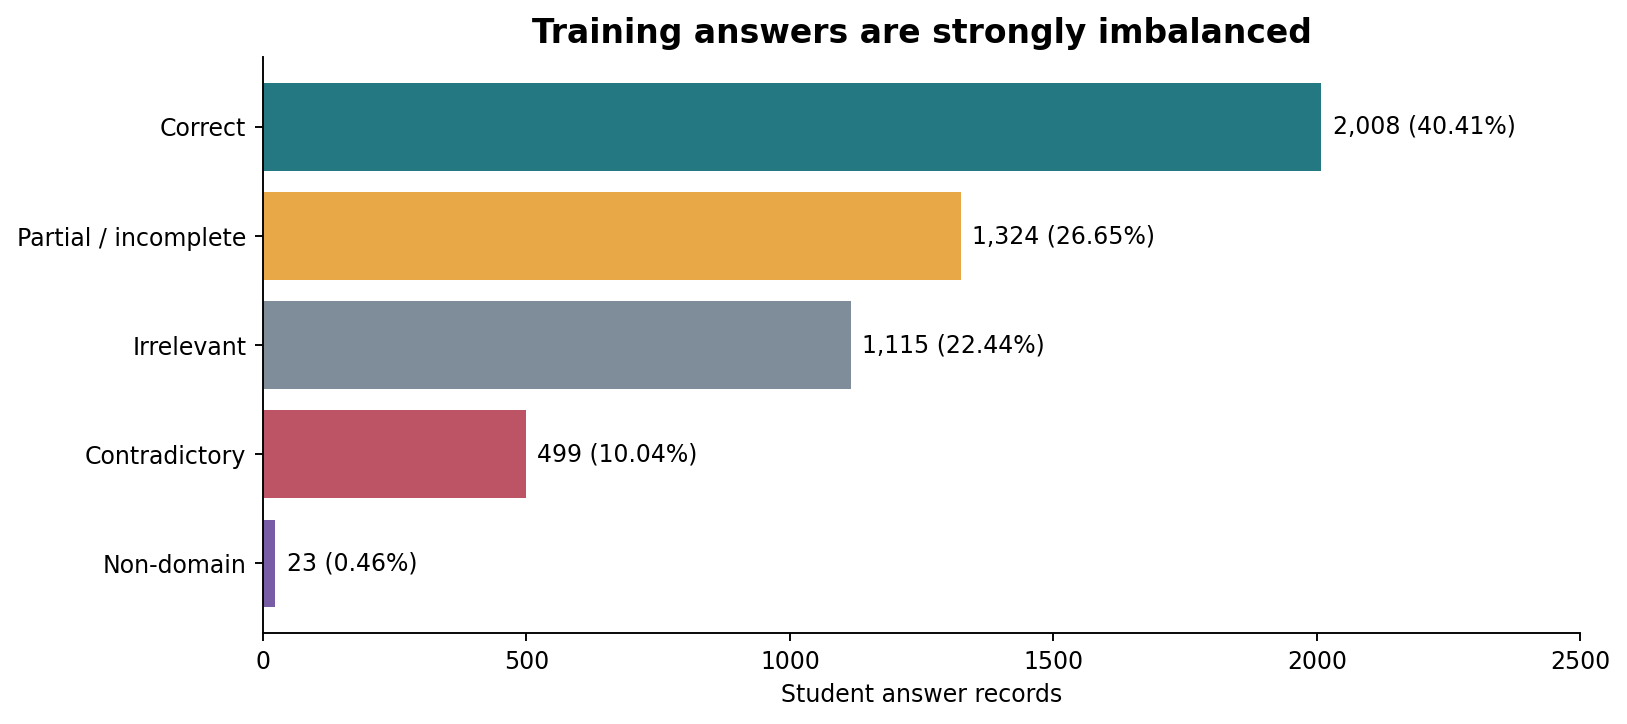

In [3]:
display(Image(filename=str(ROOT / "reports/figures/01_class_distribution.png")))

## 2. Domain counts

Each cell is an answer-record count. Domain codes are retained from the source rather than expanded into unverified names.

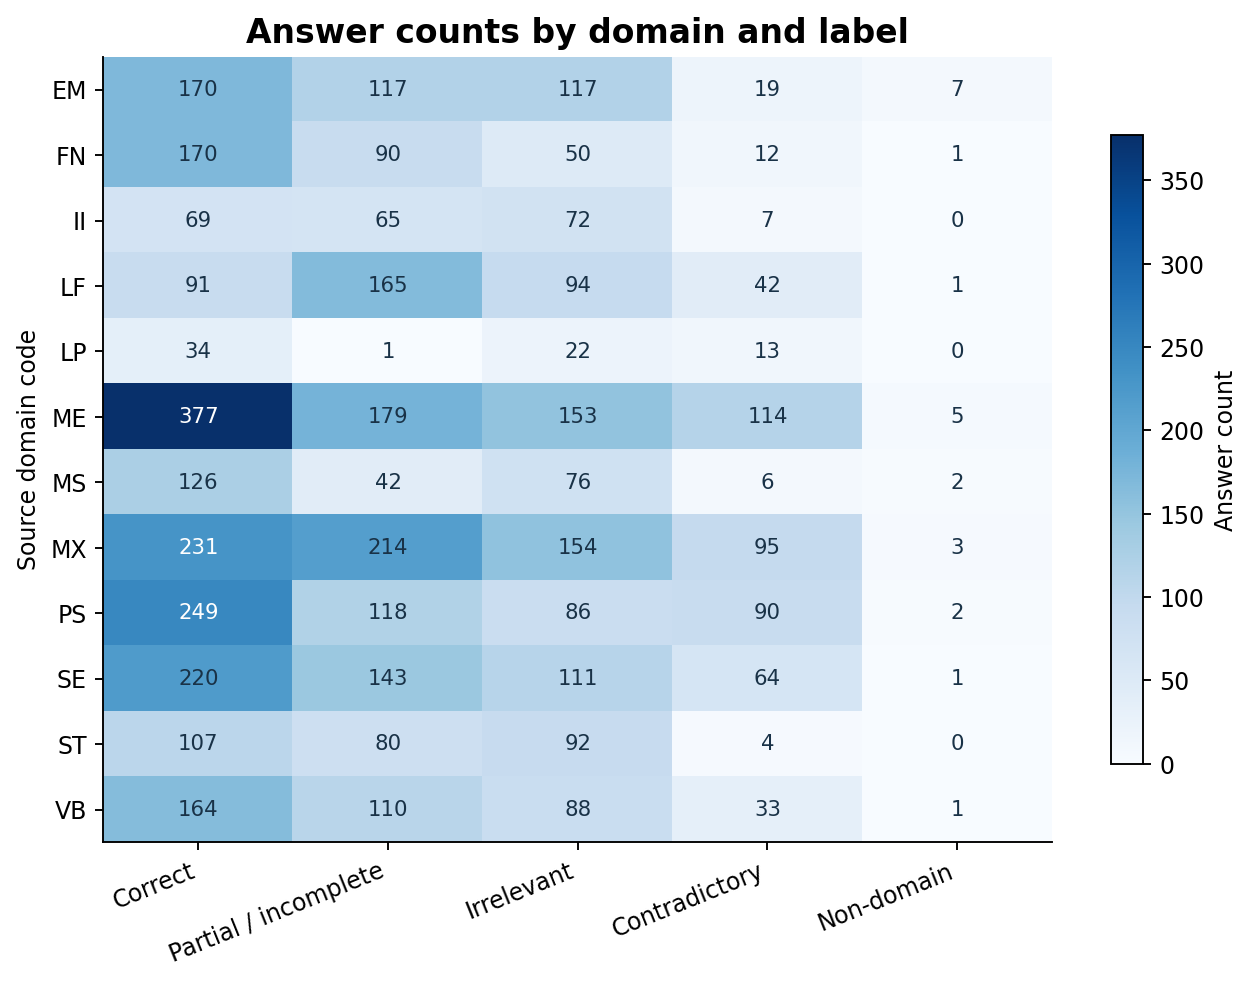

In [4]:
display(Image(filename=str(ROOT / "reports/figures/02_domain_label_counts.png")))

## 3. Within-domain shares

Each row sums to 100%. This removes domain sample-size differences but does not remove uncertainty from small domains. Read it alongside the counts.

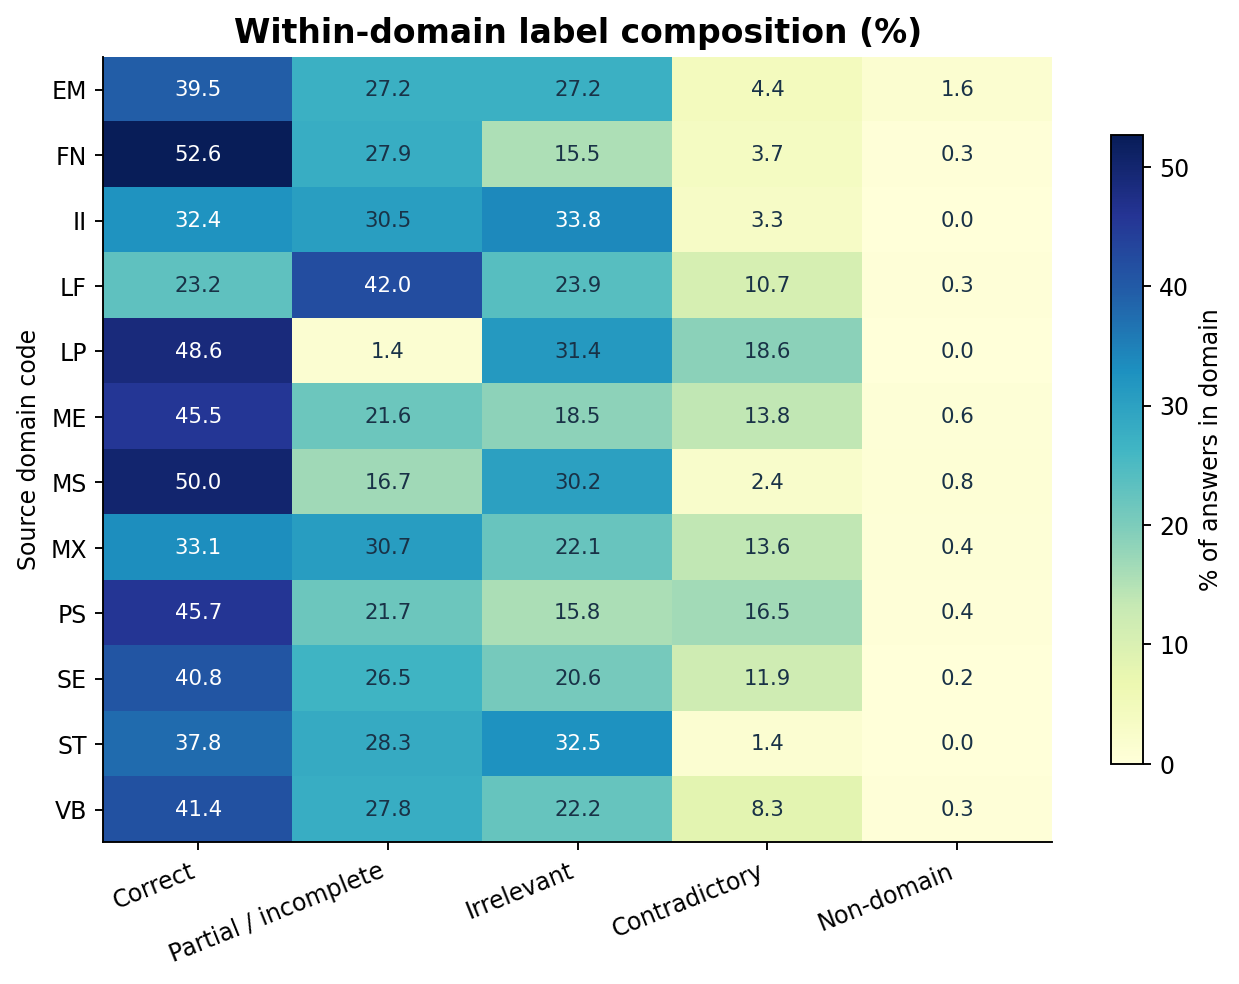

In [5]:
display(Image(filename=str(ROOT / "reports/figures/03_domain_label_shares.png")))

## 4. Answer-length distributions

Whitespace-separated word count is a transparent length measure. Each curve uses its own class denominator; the non-domain curve has only 23 records. The pooled median is 11 words.

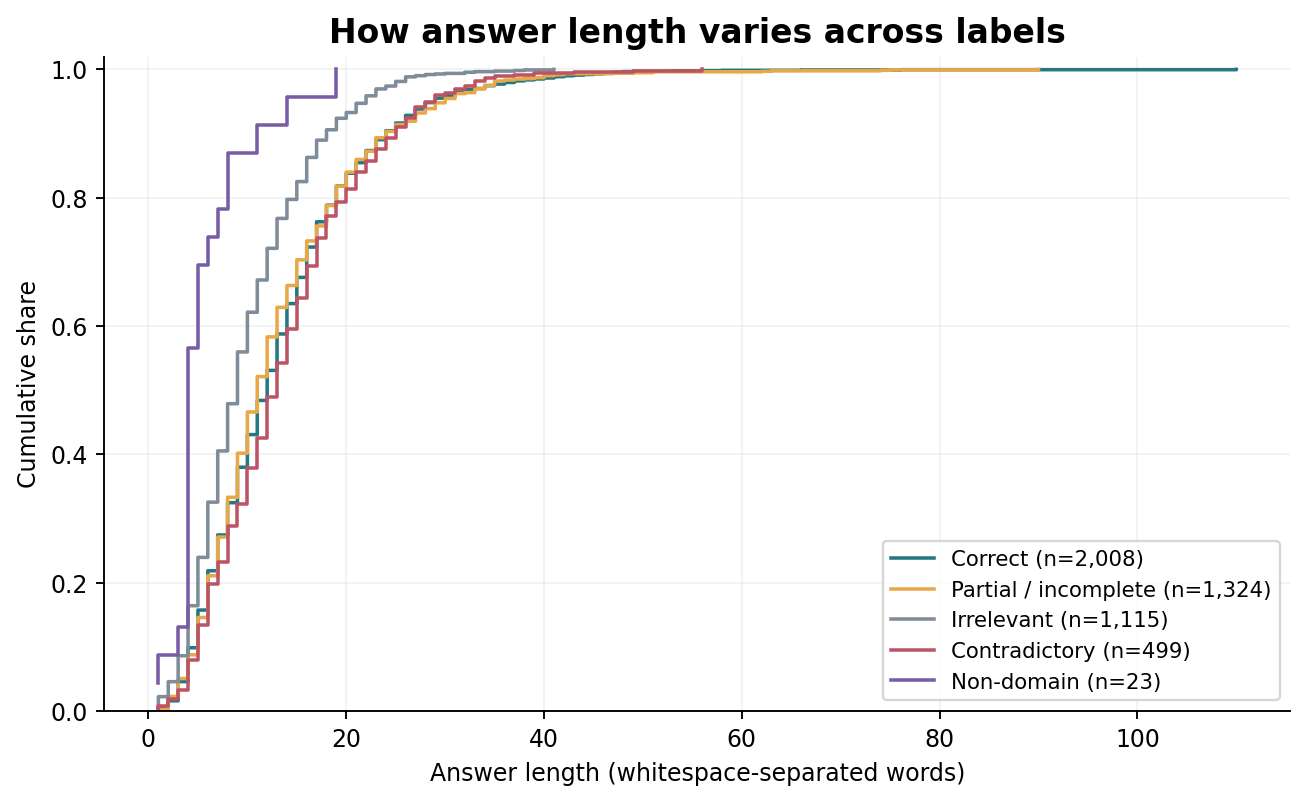

In [6]:
display(Image(filename=str(ROOT / "reports/figures/04_answer_length_ecdf.png")))

## 5. Length and outliers

The boxes summarize quartiles; points outside the whiskers are retained observations. No record is removed simply because it is long.

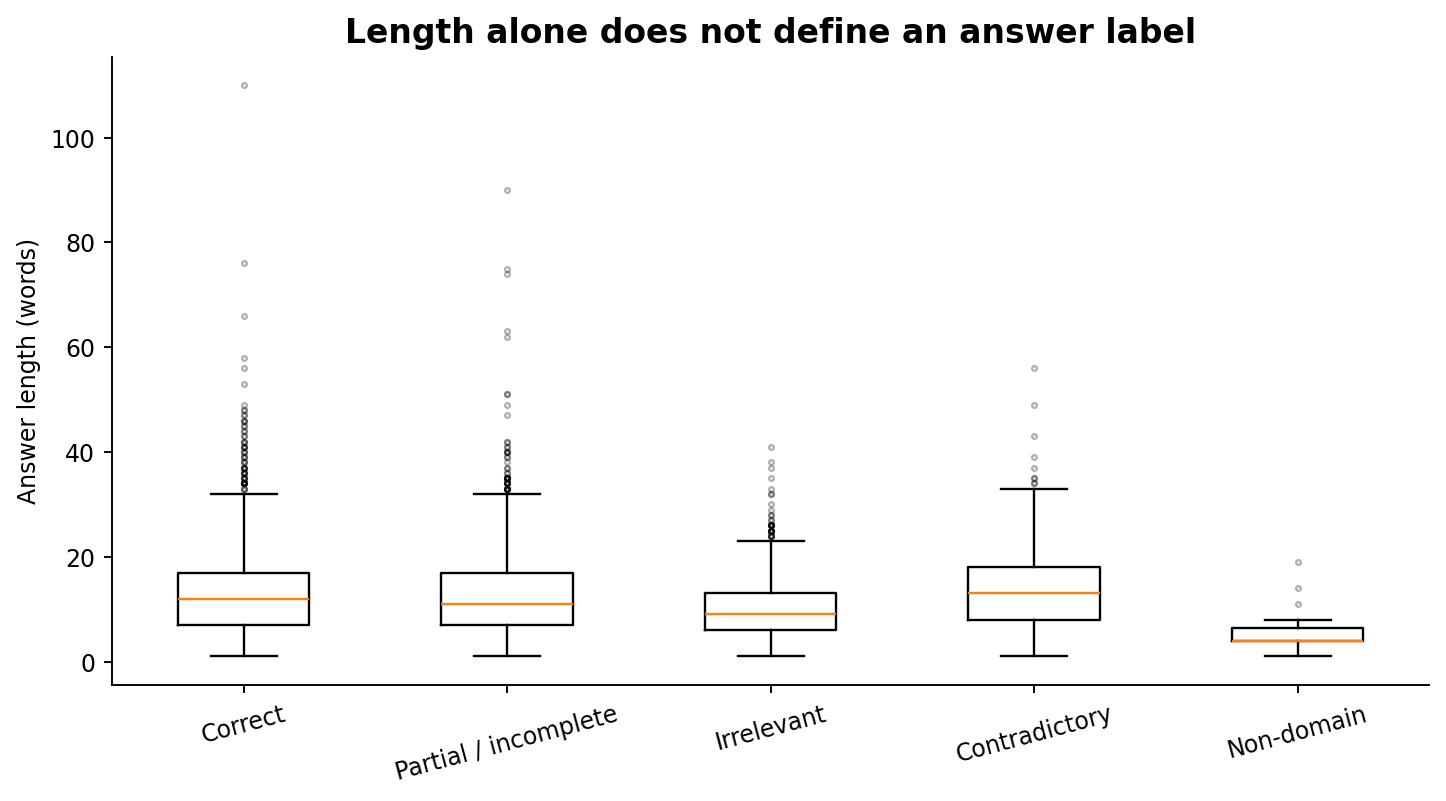

In [7]:
display(Image(filename=str(ROOT / "reports/figures/05_answer_length_boxplot.png")))

## 6. Reference-answer lexical overlap

Jaccard similarity equals the intersection divided by the union of lower-case word sets. Stop words are retained. Lexical overlap is not a semantic correctness score.

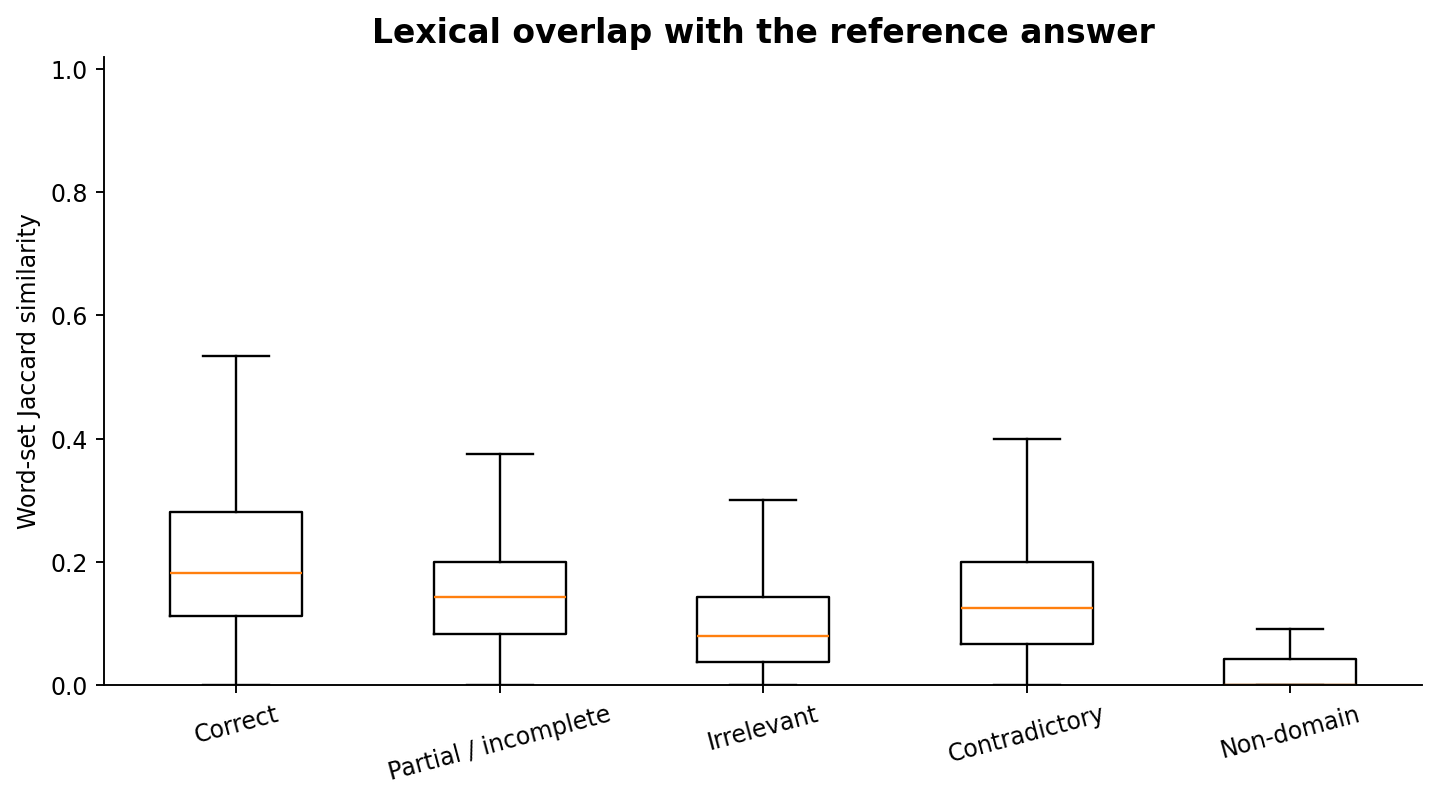

In [8]:
display(Image(filename=str(ROOT / "reports/figures/06_reference_overlap.png")))

## 7. Unequal question contributions

Questions are ranked by answer count. This is not a time series. Unequal contributions motivate an additional question-weighted analysis.

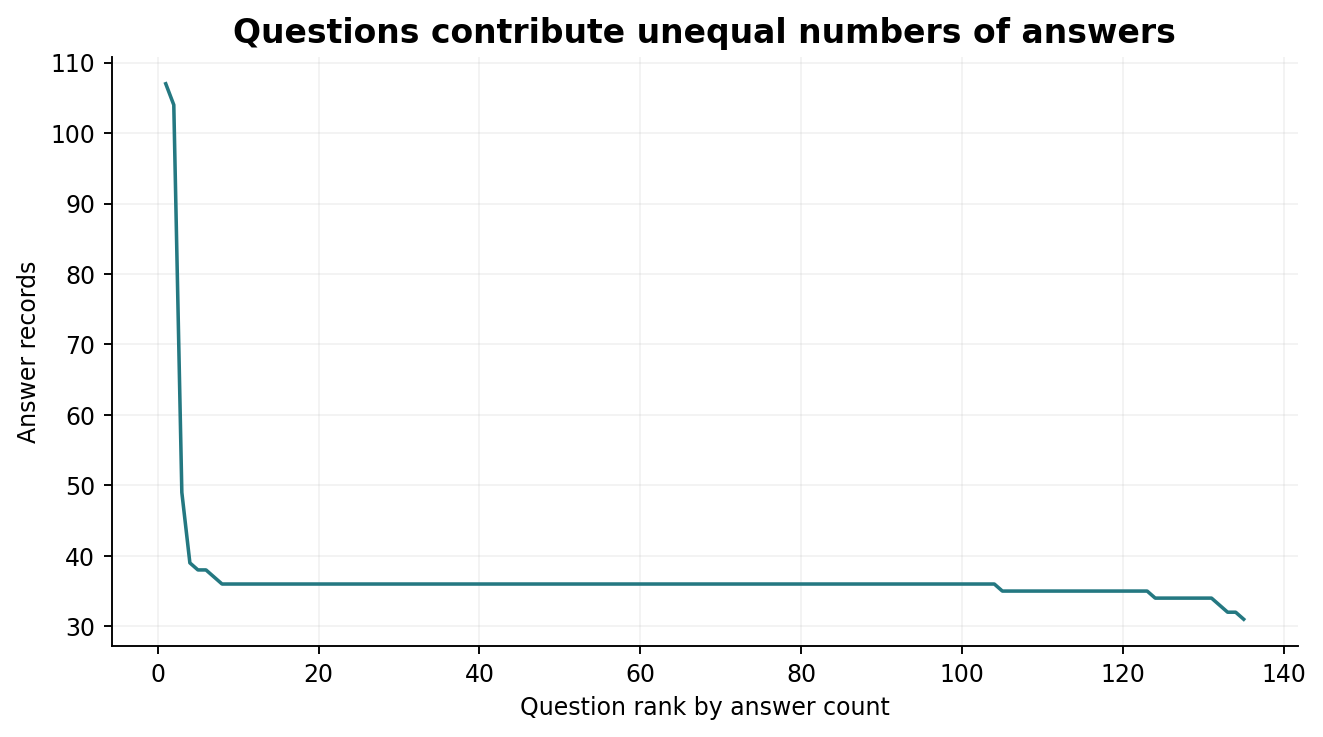

In [9]:
display(Image(filename=str(ROOT / "reports/figures/07_question_sample_sizes.png")))

## 8. Question-level label diversity

Each point is a question. Entropy summarizes diversity in the observed labels, not latent student ability or a validated question-difficulty scale. Class share and entropy are derived from the same labels.

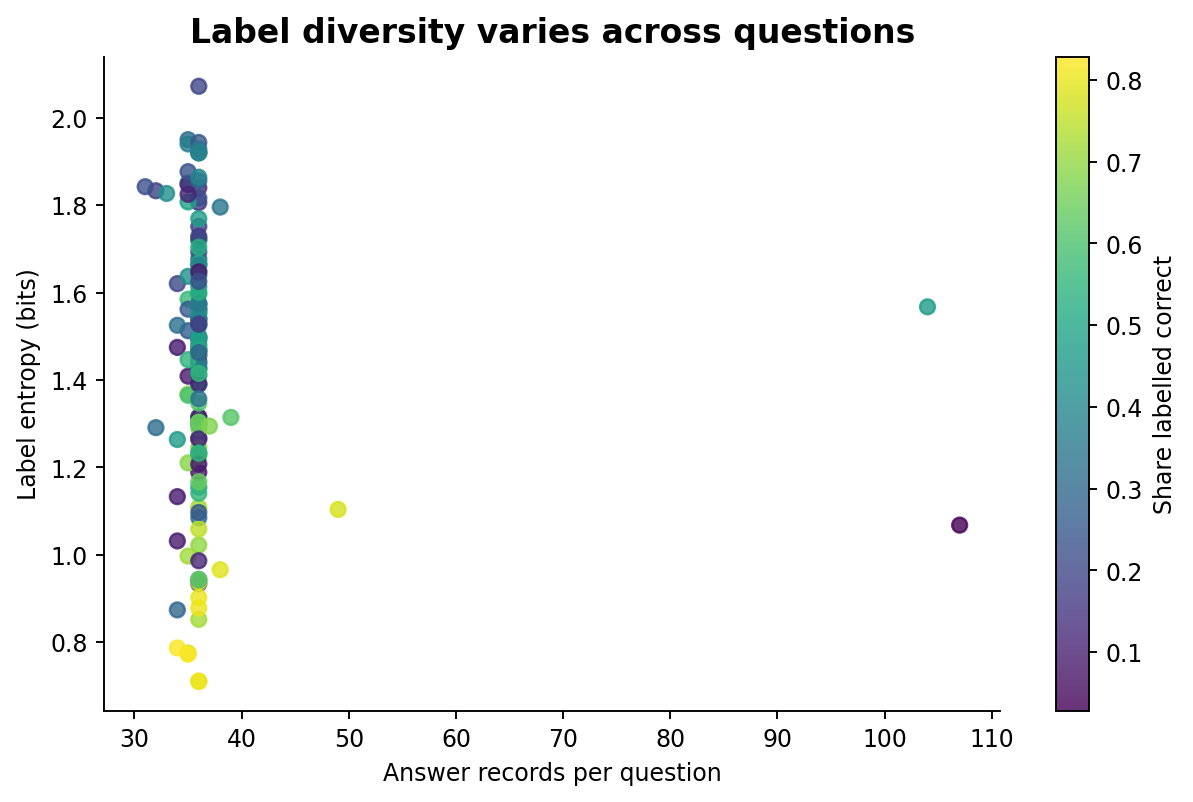

In [10]:
display(Image(filename=str(ROOT / "reports/figures/08_question_label_diversity.png")))

## 9. Minority-class concentration

Counts and within-domain rates use different denominators. Non-domain records occur in 9 of the 12 training domains and 19 of the 135 questions.

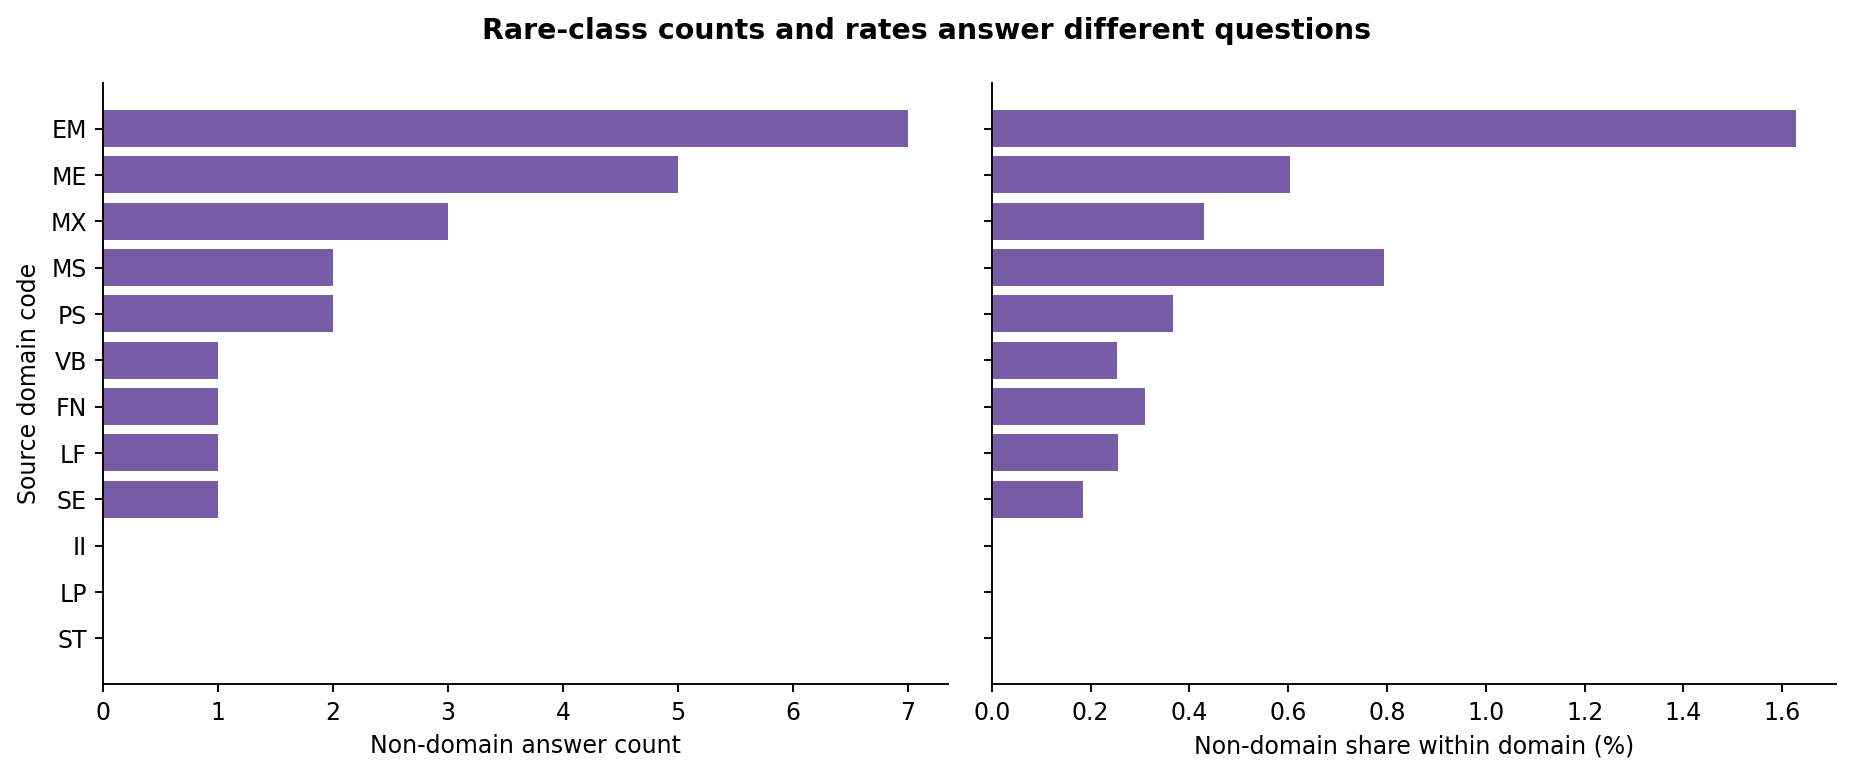

In [11]:
display(Image(filename=str(ROOT / "reports/figures/09_minority_domain_distribution.png")))

## 10. Repeated inputs

The left panel uses a log count axis so repeated groups remain visible. The right panel separates unique normalized inputs from excess repeated rows. Repetition can reflect independent submissions.

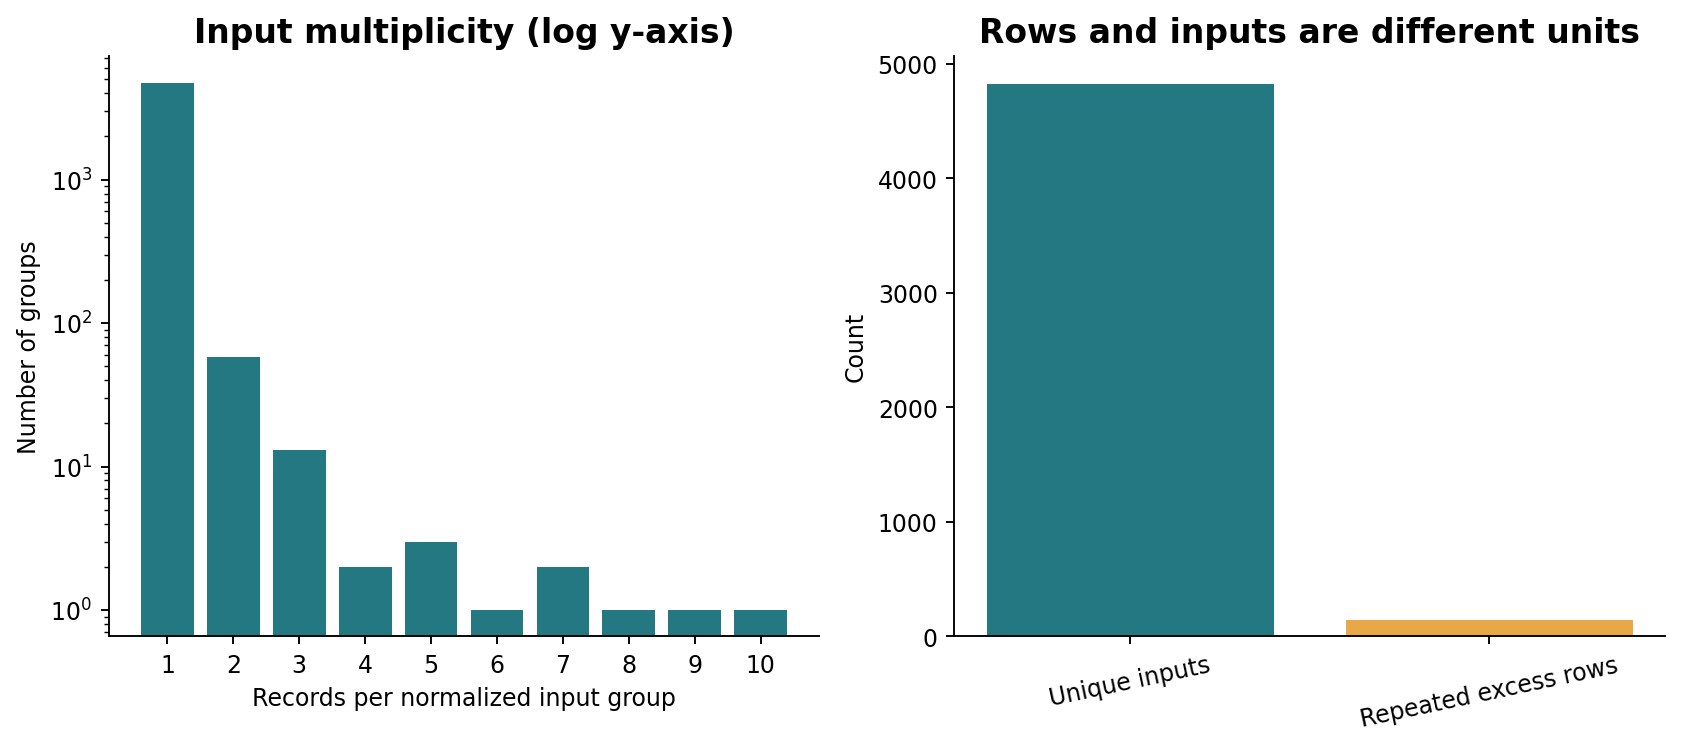

In [12]:
display(Image(filename=str(ROOT / "reports/figures/10_duplicate_structure.png")))

## 11. Conflicting annotations

Six normalized complete-input groups contain more than one label. Inspect the corresponding table before considering any relabelling; the release preserves all original labels.

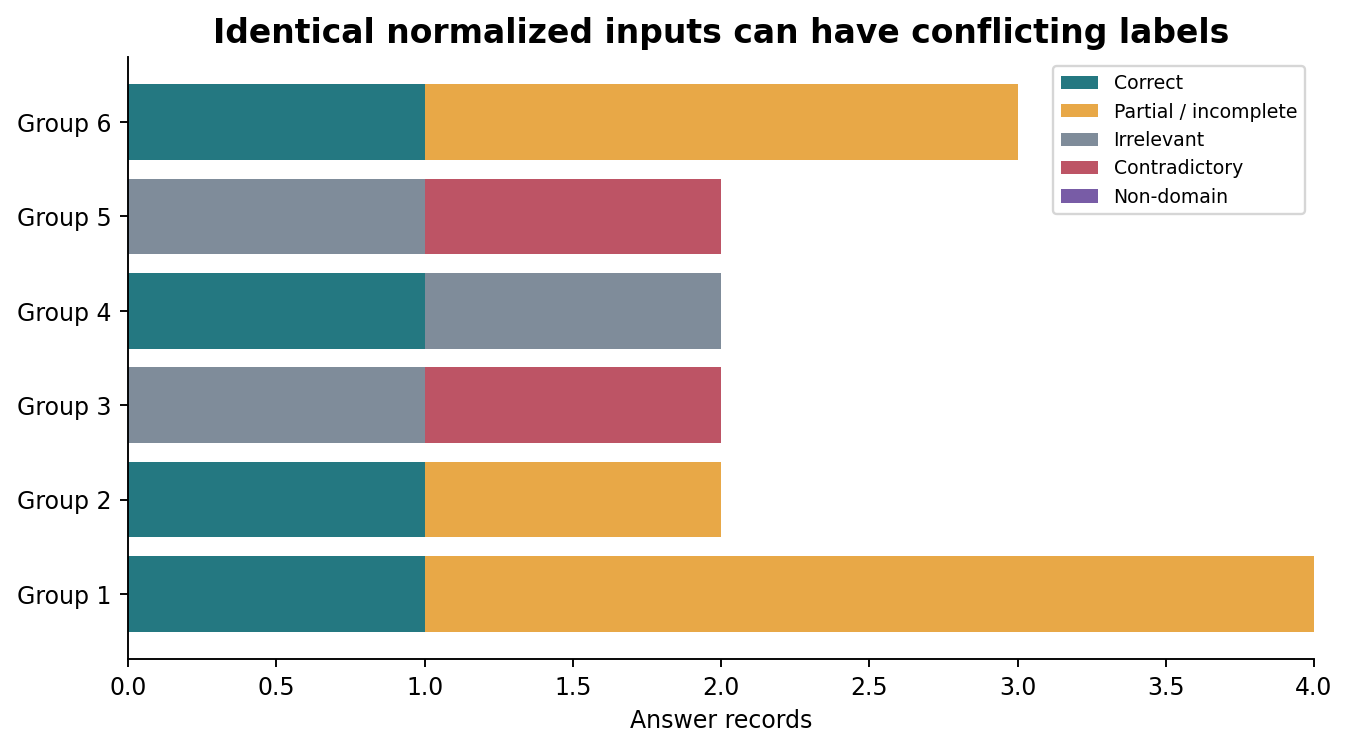

In [13]:
display(Image(filename=str(ROOT / "reports/figures/11_label_conflicts.png")))

## 12. Negation markers

The listed words and contractions are lexical flags. Scientific contradiction can occur without them, and correct explanations can contain them. This indicator is not a contradiction classifier.

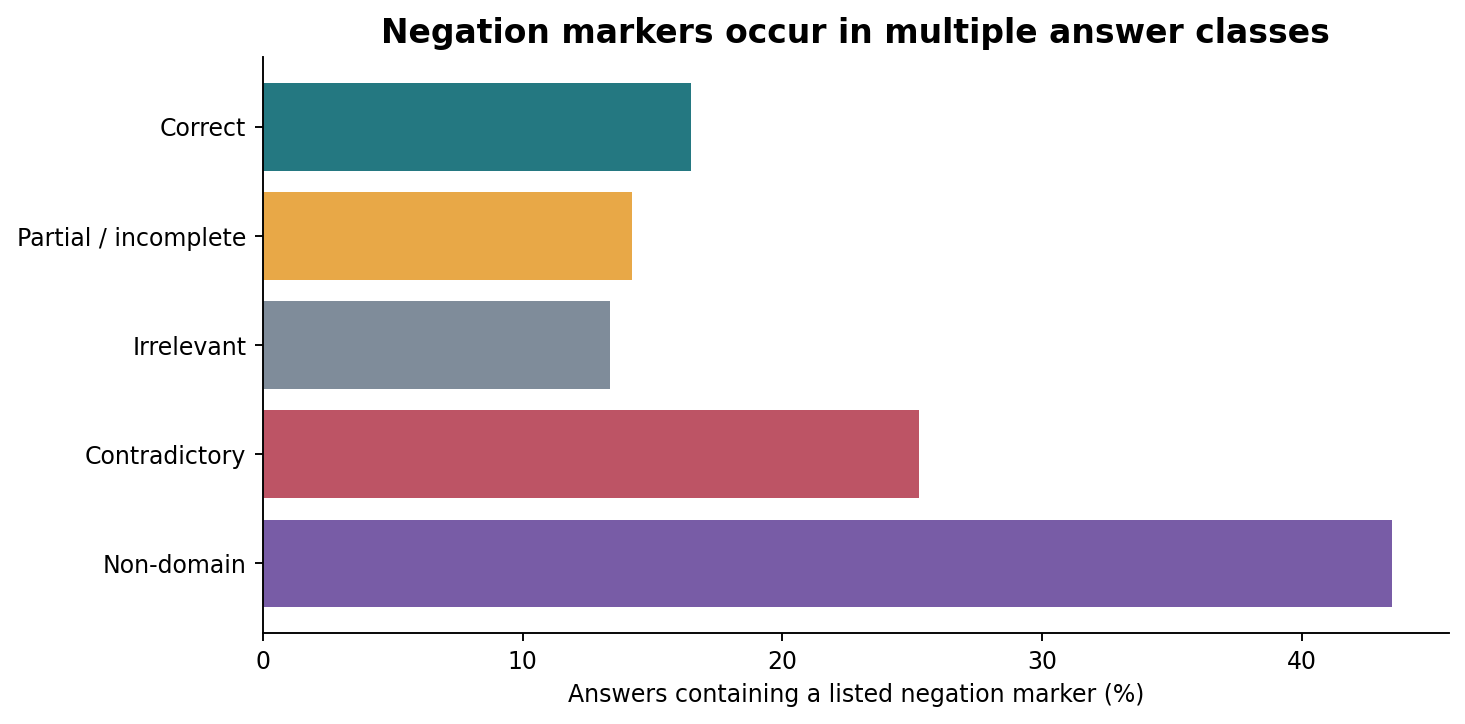

In [14]:
display(Image(filename=str(ROOT / "reports/figures/12_negation_markers.png")))

## 13. Aggregation choices

Answer-weighted shares pool all records. Question-weighted shares average within-question shares with equal weight per question. Neither estimates a unique-student distribution.

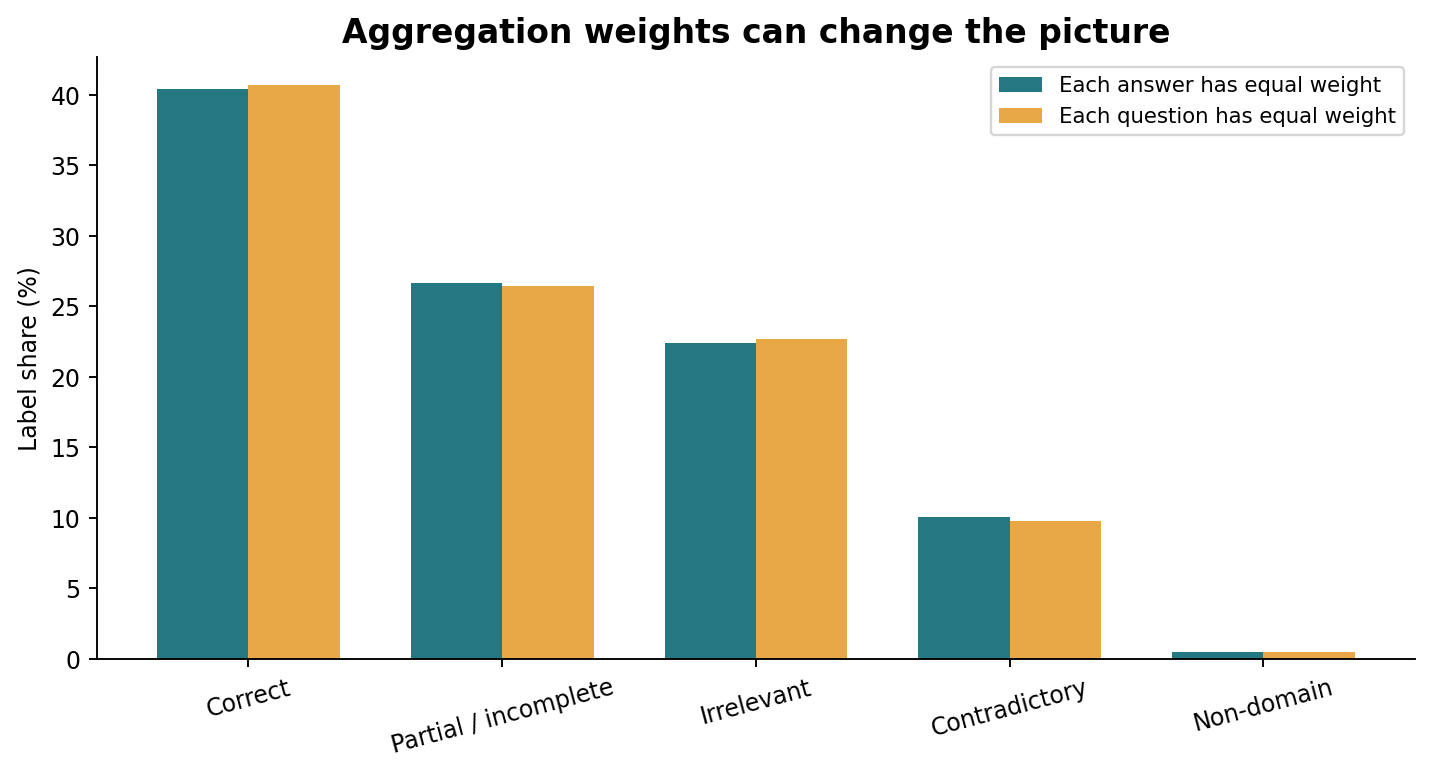

In [15]:
display(Image(filename=str(ROOT / "reports/figures/13_answer_vs_question_weighting.png")))

## 14. Overlap across domains

Domain differences may reflect vocabulary, references, questions, or annotation. This descriptive plot cannot identify which mechanism caused them.

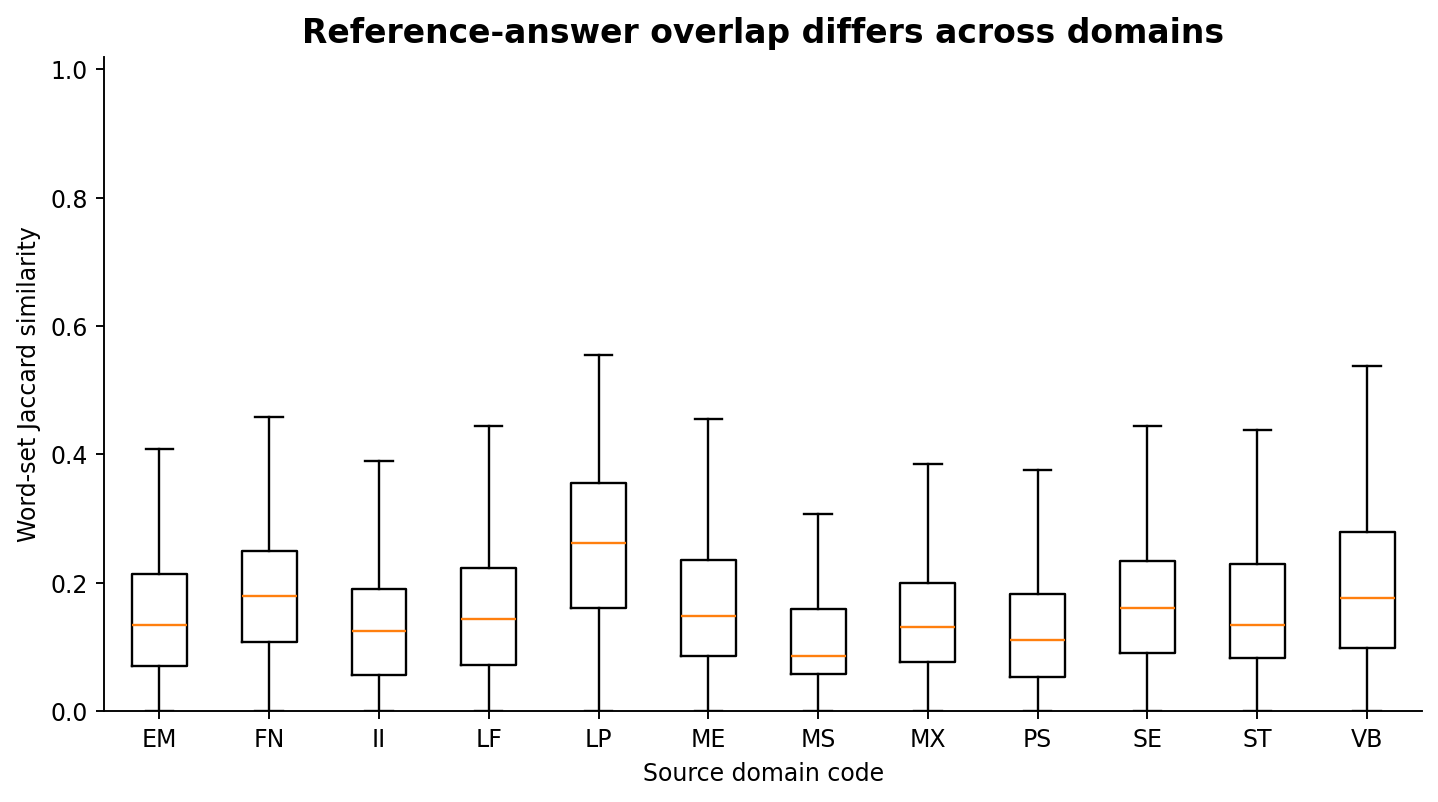

In [16]:
display(Image(filename=str(ROOT / "reports/figures/14_domain_reference_overlap.png")))

## Supporting numeric tables

In [17]:
display(pd.read_csv(ROOT / "reports/tables/text_feature_summary.csv", header=[0, 1], index_col=0))
display(pd.read_csv(ROOT / "reports/tables/weighting_comparison.csv"))

answer_word_count             ... reference_token_jaccard          
                                         count       mean  ...                     75%       max
label                                                      ...                                  
correct                                 2008.0  13.384960  ...                0.280000  1.000000
partially_correct_incomplete            1324.0  13.202417  ...                0.200000  0.555556
irrelevant                              1115.0   9.993722  ...                0.142857  0.571429
contradictory                            499.0  13.871743  ...                0.200000  0.666667
non_domain                                23.0   5.782609  ...                0.042328  0.166667

[5 rows x 16 columns]

,label,answer_weighted_percentage,question_weighted_percentage
0,correct,40.410545,40.674589
1,partially_correct_incomplete,26.645200,26.437047
2,irrelevant,22.439123,22.678646
3,contradictory,10.042262,9.747370
4,non_domain,0.462870,0.462349


## Limits and follow-up

These are associations in one public English short-answer corpus, not evidence of causal effects, learner understanding, teaching impact, or applicability to Korean responses. No claims about automatic grading accuracy have been tested. Next steps, if model development resumes, are question-grouped splitting, baseline comparison, and independent final evaluation.

Data source: Dzikovska et al. (2013), https://aclanthology.org/S13-2045/. Source dataset and data-derived material: CC BY-SA 3.0. See `data/README.md`.